## 06 - Summarizer
In this notebook, we will try summarizer model to see if text summarization improves the result

In [1]:
# !pip install sentence-transformers   # this is for text embeddings
# !pip install bert-extractive-summarizer # this is for Bert summarization


In [2]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import precision_recall_fscore_support, f1_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sentence_transformers import SentenceTransformer
from summarizer import Summarizer

In [3]:
# train_fname = "../../data/splits/train.csv"
# dev_fname = "../../data/splits/dev.csv"

# new - load 50/50 splits
train_fname = "../../data/splits/train_50pc.csv"
dev_fname = "../../data/splits/dev_50pc.csv"


train_df = pd.read_csv(train_fname)
dev_df = pd.read_csv(dev_fname)

print("Train len =", len(train_df))
print("Dev df =", len(dev_df))

Train len = 83
Dev df = 83


In [4]:
extra_subset_ratio = 0.8 # use a subset of Pitt dataset. Set to 1.0 to use full set

# extra_train_df = pd.read_csv("../../data/splits/train_pitt.csv").sample(frac=extra_subset_ratio, random_state=42)
# extra_train_df.head()
# print("Extra df len =", len(extra_train_df))

In [5]:
train_df.head()

,file_id,text,target
0,adrso021,"Everything you see going on in this picture, g...",CN
1,adrso265,"Now you just look at the picture. Okay, this i...",CN
2,adrso237,Tell me everything that you see going on in th...,AD
3,adrso197,Girls and boys getting her one that stores sto...,AD
4,adrso017,"All right, we have a few more tasks to go thro...",CN


In [6]:
dev_df.head()

,file_id,text,target
0,adrso025,Tell me everything that's going on\n\n\n\nthe ...,AD
1,adrso028,She will find her mother worship trying to dis...,AD
2,adrso032,What's going on well the children are climbing...,AD
3,adrso035,Okay here's the picture tell me I'll tell you ...,AD
4,adrso036,Tell me what's going on\n\n\n\nall the action ...,AD


### Pre-processing
We will lowercase the text for better efficiency

In [7]:
# extra_train_df["text_lower"] = extra_train_df["text"].apply(lambda text: text.lower().strip())

In [8]:
train_df["text_lower"] = train_df["text"].apply(lambda text: text.lower().strip())
dev_df["text_lower"] = dev_df["text"].apply(lambda text: text.lower().strip())

In [9]:
# extra_train_df.head()

In [10]:
train_df.head()

,file_id,text,target,text_lower
0,adrso021,"Everything you see going on in this picture, g...",CN,"everything you see going on in this picture, g..."
1,adrso265,"Now you just look at the picture. Okay, this i...",CN,"now you just look at the picture. okay, this i..."
2,adrso237,Tell me everything that you see going on in th...,AD,tell me everything that you see going on in th...
3,adrso197,Girls and boys getting her one that stores sto...,AD,girls and boys getting her one that stores sto...
4,adrso017,"All right, we have a few more tasks to go thro...",CN,"all right, we have a few more tasks to go thro..."


In [11]:
dev_df.head()

,file_id,text,target,text_lower
0,adrso025,Tell me everything that's going on\n\n\n\nthe ...,AD,tell me everything that's going on\n\n\n\nthe ...
1,adrso028,She will find her mother worship trying to dis...,AD,she will find her mother worship trying to dis...
2,adrso032,What's going on well the children are climbing...,AD,what's going on well the children are climbing...
3,adrso035,Okay here's the picture tell me I'll tell you ...,AD,okay here's the picture tell me i'll tell you ...
4,adrso036,Tell me what's going on\n\n\n\nall the action ...,AD,tell me what's going on\n\n\n\nall the action ...


### Apply summarizer model to shorten the text

In [12]:
sum_model = Summarizer()



In [13]:
# test text
s = """
For the last 20 years, I've had the same two alarms set ever weekday — one at 5:15 a.m. and one at 9:17 a.m.

As a Texas high school teacher, the 5:15 alarm is really just a formality. After 20 years of early rising, I'm up before the sun with no prompting required. The 9:17 a.m. alarm is also deeply ingrained; it's the official attendance time when I'm required to pause my instruction and take attendance. It's Texas' official "time of record" by which schools are funded on daily attendance.

It's the schedule I've followed for two decades. But after this week, neither time will matter. I will walk away from teaching and into early retirement at 59, which makes me more than a little nervous.

My income will now be cut in half
I'm unnerved by several things. I'll be "living smaller" on less income. With my pension, my income will be less than half what it has been. My expenses will be lower but won't be cut by 50%.

I've been a remote adjunct instructor at a local community college for the past year, concurrent with my high school job, but the rules of my pension require me to sit out this Fall semester. It took me years of applying to secure that adjunct position. I worry that being forced to sit out the busiest semester of the academic calendar will push me to the back of the adjunct line once again. The pay isn't great, at about $50 per hour, but a few classes certainly can help close the gap in my income

"""
summary = sum_model(s, num_sentences=4)
print(summary)

C:\Users\Minh UBC\miniconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
C:\Users\Minh UBC\miniconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
found 0 physical cores < 1
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Minh UBC\miniconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 282, in _count_physical_cores
    raise ValueError(f"found {cpu_count_physical} physical cores < 1")
C:\Users\Minh UBC\miniconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1440: UserWarning: KMeans is known to have a memory leak on Windows with MKL,

For the last 20 years, I've had the same two alarms set ever weekday — one at 5:15 a.m. and one at 9:17 a.m.

As a Texas high school teacher, the 5:15 alarm is really just a formality. The 9:17 a.m. alarm is also deeply ingrained; it's the official attendance time when I'm required to pause my instruction and take attendance. My income will now be cut in half
I'm unnerved by several things. It took me years of applying to secure that adjunct position.


In [14]:
import warnings
# hide warnings
warnings.filterwarnings('ignore')

In [15]:
summ_f = lambda text: f"{text.lower()}. Summary: {sum_model(text).lower()}"

In [16]:
# apply summary to dataframes
n_sent = 4
print("Performing summarization")
print("train set...")
# train_df["text_lower"] = train_df["text"].apply(lambda text: sum_model(text, num_sentences=n_sent).lower())
# train_df["text_lower"] = train_df["text"].apply(lambda text: sum_model(text).lower())

# try concate the summary
train_df["text_lower"] = train_df["text"].apply(summ_f)


print("dev set...")
# dev_df["text_lower"] = dev_df["text"].apply(lambda text: sum_model(text, num_sentences=n_sent).lower())
# dev_df["text_lower"] = dev_df["text"].apply(lambda text: sum_model(text).lower())
dev_df["text_lower"] = dev_df["text"].apply(summ_f)

# print("train set...")
# dev_df["text_lower"] = dev_df["text"].apply(lambda text: sum_model(text, num_sentences=n_sent).lower())


print("Completed")


Performing summarization
train set...
dev set...
Completed


In [17]:
# stack up extra-train and train df

# stacked_train_df = pd.concat([train_df, extra_train_df], ignore_index=True, axis=0)

# test with pre-train with extra data only
stack = False  # set to True to combine train_df with extra_train_df
replace = False # set to True to replace train df with extra_train_df (Pitt dataset)

# the combination stack=False and replace=True works best, accuracy=85%, recall=97%
if replace:
    stacked_train_df = extra_train_df
elif stack:
    stacked_train_df = pd.concat([train_df, extra_train_df], ignore_index=True, axis=0)
else:
    # keep the original train_df
    stacked_train_df = train_df

print(len(stacked_train_df))
stacked_train_df.head()

83


,file_id,text,target,text_lower
0,adrso021,"Everything you see going on in this picture, g...",CN,"everything you see going on in this picture, g..."
1,adrso265,"Now you just look at the picture. Okay, this i...",CN,"now you just look at the picture. okay, this i..."
2,adrso237,Tell me everything that you see going on in th...,AD,tell me everything that you see going on in th...
3,adrso197,Girls and boys getting her one that stores sto...,AD,girls and boys getting her one that stores sto...
4,adrso017,"All right, we have a few more tasks to go thro...",CN,"all right, we have a few more tasks to go thro..."


### Build Tfidf Vectorizer

We can use Tfidf Vectorizer to convert text to a fixed-length vector

In [18]:
vectorizer = TfidfVectorizer(max_features=10000,
                             # ngram_range=(1, 4),
                            )

# corpus = train_df["text_lower"]
corpus = stacked_train_df["text_lower"]
print(len(corpus))
print("Building Tfidf Vectorizer...")
X_train = vectorizer.fit_transform(corpus)
print("Completed")

83
Building Tfidf Vectorizer...
Completed


In [19]:
print(X_train.shape)

(83, 950)


### Create transformer-based sentence embeddings


In [20]:
# vectorizer_embed = SentenceTransformer("all-MiniLM-L12-v2")
# vectorizer_embed = SentenceTransformer("sentence-t5-large") # works best
# vectorizer_embed = SentenceTransformer("all-mpnet-base-v2")
# model = SentenceTransformer("intfloat/e5-mistral-7b-instruct")

# vectorizer_embed = SentenceTransformer("sentence-t5-xl") 
# vectorizer_embed = SentenceTransformer("all-roberta-large-v1") # works better and more consistent than sentence-T5-large
# vectorizer_embed = SentenceTransformer("sentence-t5-large") # produced 76% acc, 97% recall with text summarization

# vectorizer_embed = SentenceTransformer("all-distilroberta-v1") # produced 69% accuracy, 100% recall, with T5 for train
# vectorizer_embed = SentenceTransformer("multi-qa-distilbert-cos-v1") # produced 70% accuracy, 100% recall, with T5 for train
vectorizer_embed = SentenceTransformer("LaBSe") # 85% acc, 94% recall

In [21]:
corpus = stacked_train_df["text_lower"]
print("Creating text embeddings...")
X_train_embed = vectorizer_embed.encode(corpus)
# X_train = vectorizer.encode(corpus,
#                             # prompt="Does this person have Alzheimer's Disease (yes/no)?"
#                             prompt="Represent the Medical paragraph for Alzheimer's Disease classification:"
#                            )
print("Completed")


Creating text embeddings...
Completed


In [22]:
print(type(X_train_embed))
print(X_train_embed.shape)

<class 'numpy.ndarray'>
(83, 768)


In [23]:
# double check Tfidf vector
print(type(X_train_embed))
print(X_train.shape)

<class 'numpy.ndarray'>
(83, 950)


#### Concate 2 vectors (Tfidf + sentence embeddings)


In [24]:
# test
v1 = [[2, 4, 6],
      [1, 3, 5]
     ]
v2 = [[8, 10],
      [7, 9]
     ]
v3 = np.concatenate((v1, v2), axis=1) # concate on horizontal axis
print(v3) # should be [2, 4, 6, 8, 10], [1, 3, 5, 7, 9]

[[ 2  4  6  8 10]
 [ 1  3  5  7  9]]


In [25]:
concat_train = True
if concat_train:
    X_train = np.concatenate((X_train.toarray(), X_train_embed),
                             axis=1
                            )
    # X_train = np.concatenate((X_train_embed, X_train.toarray()),
    #                          axis=1
    #                         )

print(X_train.shape)

(83, 1718)


In [26]:
# switch to embedding train set
use_embeddings_only = False # set to True to use embedding only, ignoring Tfidf
# use_embeddings_only = True # set to True to use embedding only, ignoring Tfidf
if use_embeddings_only:
    X_train = X_train_embed
print(X_train.shape)

(83, 1718)


### Train Logistic regression using combined vector

We can now train a simple logistic regression classifier using processed X_train

In [27]:
# X_train = vectorizer.fit_transform(stacked_train_df["text_lower"])
y_train = stacked_train_df["target"]

print("Training logistic classifier...")
clf = LogisticRegression(random_state=42, max_iter=200).fit(X_train, y_train)

# some setting tweaks to lower the precision -> avoid overfitting
# clf = LogisticRegression(random_state=42, 
#                          solver="newton-cg",
#                          penalty="l2",
#                          tol=0.01,
#                          max_iter=300,
#                         ).fit(X_train, y_train)
print("Completed")

Training logistic classifier...
Completed


In [28]:
# getting score on train set
train_score = clf.score(X_train, y_train)
print(f"Train accuracy = {train_score*100:.2f} %")

Train accuracy = 91.57 %


### Get accuracy using cross validation

In [29]:
print("Performing cross-validation...")
scores = cross_val_score(clf, X_train, y_train, cv=3)
print("Completed")
print(scores)
print("Average =", np.average(scores))

Performing cross-validation...
Completed
[0.57142857 0.64285714 0.7037037 ]
Average = 0.6393298059964727


In [30]:
# get precision / recall / f1
y_pred = clf.predict(X_train)
print(classification_report(y_train, y_pred, target_names=["AD", "CN"]))

              precision    recall  f1-score   support

          AD       0.90      0.96      0.93        47
          CN       0.94      0.86      0.90        36

    accuracy                           0.92        83
   macro avg       0.92      0.91      0.91        83
weighted avg       0.92      0.92      0.92        83



### Now we can evaluate on dev set

In [31]:
use_diff_embed_dev = False # set to True to use different embed models for train and dev
# use_diff_embed_dev = True # set to True to use different embed models for train and dev
if use_diff_embed_dev:
    # vectorizer_embed = SentenceTransformer("all-mpnet-base-v2") 
    vectorizer_embed = SentenceTransformer("all-distilroberta-v1") 
    # vectorizer_embed = SentenceTransformer("multi-qa-distilbert-cos-v1") # produced 69% accuracy, 100% recall, with T5 for train set

In [32]:
X_dev = vectorizer.transform(dev_df["text_lower"])
y_dev = dev_df["target"]
print("X_dev shape =", X_dev.shape)
print("y_dev len =", len(y_dev))

X_dev shape = (83, 950)
y_dev len = 83


In [33]:
# create X_dev embeddings
print("Creating text embeddings...")
X_dev_embed = vectorizer_embed.encode(dev_df["text_lower"])
print("Completed")

Creating text embeddings...
Completed


In [34]:
print(type(X_dev_embed))
print(X_dev_embed.shape)

<class 'numpy.ndarray'>
(83, 768)


In [35]:
# double check Tfidf vector
print(type(X_dev))
print(X_dev.shape)

<class 'scipy.sparse._csr.csr_matrix'>
(83, 950)


In [36]:
if concat_train:
    X_dev = np.concatenate((X_dev.toarray(), X_dev_embed),
                             axis=1
                            )
    # X_dev = np.concatenate((X_dev_embed, X_dev.toarray()),
    #                          axis=1
    #                         )

if use_embeddings_only:
    X_dev = X_dev_embed

print(X_dev.shape)

(83, 1718)


In [37]:
dev_score = clf.score(X_dev, y_dev)
print(f"Dev accuracy = {dev_score*100:.2f} %")

Dev accuracy = 77.11 %


In [38]:
y_pred = clf.predict(X_dev)
print(classification_report(y_dev, y_pred, target_names=["AD", "CN"]))

              precision    recall  f1-score   support

          AD       0.72      0.85      0.78        40
          CN       0.83      0.70      0.76        43

    accuracy                           0.77        83
   macro avg       0.78      0.77      0.77        83
weighted avg       0.78      0.77      0.77        83



The baseline result has improved with additional data from Pitt:
- Accuracy improved to 78% compared with 74% in previous baseline
- Recall improved to 89%, compared with 76% in previous baseline
- Average 10-fold accuracy improved to 80% from 76% 

If we pre-train with Pitt dataset only, without using our train set at all:
- the accuracy dropped slightly from 79% to 77%
- but recall improved from 90% to 94%

In [39]:
### Process prediction for test set

In [40]:
test_fname = "../../data/splits/test_text.csv"
test_df = pd.read_csv(test_fname)
print("Test df =", len(test_df))
test_df["text_lower"] = test_df["text"].apply(lambda text: text.lower().strip())
test_df.head()

Test df = 71


,ID,Prediction,text,text_lower
0,adrsdt15,NaN,"I see oh boy, almost falling on a stool trying...","i see oh boy, almost falling on a stool trying..."
1,adrsdt40,NaN,Well the kids are trying to get the cookies an...,well the kids are trying to get the cookies an...
2,adrsdt26,NaN,"Okay, this is a family setting in a kitchen an...","okay, this is a family setting in a kitchen an..."
3,adrsdt67,NaN,"Oh, what do I see in this picture? This remind...","oh, what do i see in this picture? this remind..."
4,adrsdt58,NaN,While the young boy is reaching for a cookie j...,while the young boy is reaching for a cookie j...


In [41]:
# add summarization
print("Performing summarization")
print("Test set...")
# test_df["text_lower"] = test_df["text"].apply(lambda text: sum_model(text, num_sentences=n_sent).lower())
# test_df["text_lower"] = test_df["text"].apply(lambda text: sum_model(text).lower())
test_df["text_lower"] = test_df["text"].apply(summ_f)
# print("train set...")
# dev_df["text_lower"] = dev_df["text"].apply(lambda text: sum_model(text, num_sentences=n_sent).lower())


print("Completed")
test_df.head()

Performing summarization
Test set...
Completed


,ID,Prediction,text,text_lower
0,adrsdt15,NaN,"I see oh boy, almost falling on a stool trying...","i see oh boy, almost falling on a stool trying..."
1,adrsdt40,NaN,Well the kids are trying to get the cookies an...,well the kids are trying to get the cookies an...
2,adrsdt26,NaN,"Okay, this is a family setting in a kitchen an...","okay, this is a family setting in a kitchen an..."
3,adrsdt67,NaN,"Oh, what do I see in this picture? This remind...","oh, what do i see in this picture? this remind..."
4,adrsdt58,NaN,While the young boy is reaching for a cookie j...,while the young boy is reaching for a cookie j...


In [42]:
X_test = vectorizer.transform(test_df["text_lower"])


In [43]:
# create X_test embeddings
print("Creating text embeddings...")
X_test_embed = vectorizer_embed.encode(test_df["text_lower"])
print("Completed")

Creating text embeddings...
Completed


In [44]:
if concat_train:
    X_test = np.concatenate((X_test.toarray(), X_test_embed),
                             axis=1
                            )
    # X_test = np.concatenate((X_test_embed, X_test.toarray()),
    #                          axis=1
    #                         )
if use_embeddings_only:
    X_test = X_test_embed
    
print(X_test.shape)

(71, 1718)


In [45]:
test_df["Prediction"] = clf.predict(X_test)
test_df.head()

,ID,Prediction,text,text_lower
0,adrsdt15,CN,"I see oh boy, almost falling on a stool trying...","i see oh boy, almost falling on a stool trying..."
1,adrsdt40,CN,Well the kids are trying to get the cookies an...,well the kids are trying to get the cookies an...
2,adrsdt26,CN,"Okay, this is a family setting in a kitchen an...","okay, this is a family setting in a kitchen an..."
3,adrsdt67,AD,"Oh, what do I see in this picture? This remind...","oh, what do i see in this picture? this remind..."
4,adrsdt58,CN,While the young boy is reaching for a cookie j...,while the young boy is reaching for a cookie j...


In [46]:
# convert to 0/1 to be consistent to ground truth
label2binary = lambda label: "0" if label=="0" or label.lower().strip() == "cn" else "1"
assert label2binary("CN") == "0"
assert label2binary("AD") == "1"
assert label2binary("0") == "0"
assert label2binary("1") == "1"

print("Passed")

Passed


In [47]:
# apply to prediction column
test_df["Prediction"] = test_df["Prediction"].apply(label2binary)
# write to prediction output file
output_df = test_df.drop(columns=["text", "text_lower"])
output_df.head()

,ID,Prediction
0,adrsdt15,0
1,adrsdt40,0
2,adrsdt26,0
3,adrsdt67,1
4,adrsdt58,0


In [49]:
output_path = "../../evaluation/"
fname = "test_results_task1_summary.csv"
output_df.to_csv(output_path + fname,
                 index=False
                )
print("Completed")

Completed


### Evaluation output for test set, with Roberta + Summary

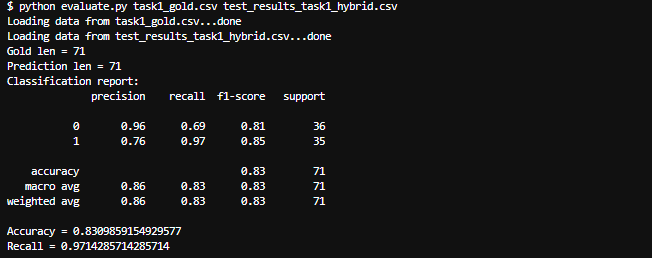

### Evaluation output for test set, with LaBSE + Summary + Original train set only

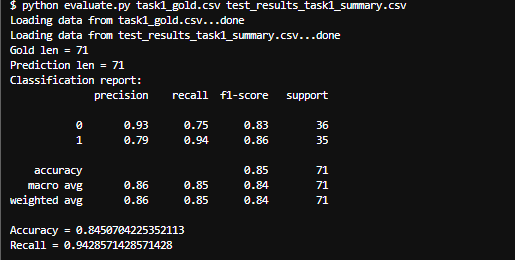